멀티 에이전트
- 에이전트에 노드를 추가하지 않고 따로 필요한 이유?
- 예) 사용할 수 있는 검색 엔진이 다수. 이를 별도의 에이전트에 담아 전문가 집단을 만드는 식

노드와 에이전트의 차이
- 노드: 그래프 안에서 실행 단위 하나. llm 포함할 수도 없이 함수일 수도.
- 에이전트: 목표를 가지고 실행 할 수 있는 시스템. 노드를 포함할 수 있는 전체적인 지능 시스템. 판단을 위해 무조건 llm이 필요

# **1. 멀티 에이전트**
- 단일 Agent가 조사, 분석, 작성, 검수까지 모두 맡으면 프롬프트가 복잡해지고, 실패 지점이나 책임을 구분하기 어려움
- 멀티 에이전트는 작업을 역할별로 나누고, 각 결과를 다음 담당자에게 전달
    - Network: 동료 간 상호 위임이 가능한 연결 구조
    - Supervisor: 여러 담당자의 순서를 결정하는 중앙 관리자
    - Hierarchical: 팀 안에 팀이 있는 계층적 조직

### HandOff
- 현재 담당자가 다른 담당자에게 실행 제어권을 넘기는 것

In [1]:
import matplotlib.pyplot as plt
import os, json

from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain_openai import ChatOpenAI
from langgraph.types import Command
from tavily import TavilyClient
from dotenv import load_dotenv
from pathlib import Path
from pydantic import BaseModel, Field

In [ ]:
load_dotenv()

if not os.getenv('OPENAI_API_KEY'):
    raise RuntimeError(".env에 openai api key 설정!")
llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "gpt-5.6-luna"), temperature=0)

In [3]:
class HandOffState(TypedDict, total=False):
    request: str
    department: str
    answer: str

def triage(state: HandOffState):
    text = state["request"].lower()
    dept = 'coding' if any(k in text for k in ('파이썬','코드','python','for문')) else 'writing'
    return {'department':dept}

def coding(state: HandOffState):
    return {"answer":f"[코딩담당]{state['request']} > 예제: for x in [1,2,3]: print(x)"}

def writing(state: HandOffState):
    return {"answer": f"[글쓰기 담당] {state['request']} > 도입/본문/마무리로 구성하세요"}

def route_handoff(state:HandOffState): # 넘길 에이전트 선택
    return state['department']

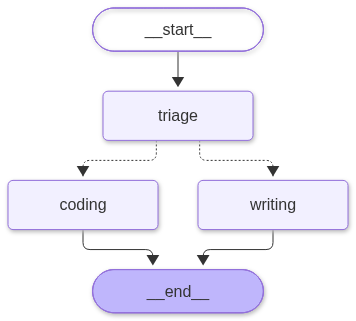

In [4]:
builder = StateGraph(HandOffState)
builder.add_node("triage", triage)
builder.add_node("coding", coding)
builder.add_node("writing", writing)
builder.add_edge(START,"triage")
builder.add_conditional_edges("triage", route_handoff, {"coding":"coding","writing":"writing"})
builder.add_edge("coding",END)
builder.add_edge("writing",END)
handoff_graph = builder.compile()
handoff_graph

In [5]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    print(handoff_graph.invoke({"request":q}))

{'request': '파이썬 for문 설명해줘', 'department': 'coding', 'answer': '[코딩담당]파이썬 for문 설명해줘 > 예제: for x in [1,2,3]: print(x)'}
{'request': '감사 인사말을 작성해줘', 'department': 'writing', 'answer': '[글쓰기 담당] 감사 인사말을 작성해줘 > 도입/본문/마무리로 구성하세요'}


In [6]:
for update in handoff_graph.stream({'request':'파이썬 리스트 예제'}, stream_mode="updates"):
    print(update)

{'triage': {'department': 'coding'}}
{'coding': {'answer': '[코딩담당]파이썬 리스트 예제 > 예제: for x in [1,2,3]: print(x)'}}


In [ ]:
llm = ChatOpenAI(model='gpt-5.6-luna', temperature=0)

# 1. 분류 에이전트
def triage(state: HandOffState) -> Command[Literal["coding","writing"]]:
    text = state["request"].lower()
    dept = 'coding' if any(k in text for k in ('파이썬','코드','python','for문')) else 'writing'
    # updates: 공유 상태(State)에 department 값을 저장. got: 다음에 실행할 노드를 지정
    return Command(update={'department':dept}, goto=dept) # Command로 다른 노드에 상태 전달

# 2. 코딩 에이전트
def coding(state: HandOffState):
    response = llm.invoke(
        f"당신은 파이썬 전문 강사입니다. 쉽게 설명하세요. \n질문: {state['request']}"
    )
    return {"answer": response.content}

# 3. 글쓰기 에이전트
def writing(state: HandOffState):
    response = llm.invoke(
        f"당신은 전문 작가입니다. 자연스럽게 글을 작성하세요.\n요청: {state['request']}"
    )
    return {"answer": response.content}

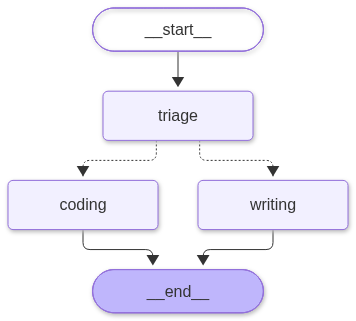

In [11]:
builder = StateGraph(HandOffState)
builder.add_node("triage",triage)
builder.add_node("coding",coding)
builder.add_node("writing",writing)
builder.add_edge(START, "triage")
builder.add_edge("coding",END)
builder.add_edge("writing",END)
graph = builder.compile()
graph

In [12]:
for q in ["파이썬 for문 설명해줘", "감사 인사말을 작성해줘"]:
    result = graph.invoke({"request":q})
    print(f'\n질문: {q}')
    print(f"담당: {result["department"]}")
    print(f"답변: {result["answer"]}")


질문: 파이썬 for문 설명해줘
담당: coding
답변: 파이썬의 `for`문은 **여러 개의 데이터를 하나씩 꺼내서 반복 처리할 때** 사용합니다.

## 1. 기본 형태

```python
for 변수 in 반복할_데이터:
    실행할_문장
```

예를 들어 리스트의 값을 하나씩 출력할 수 있습니다.

```python
fruits = ["사과", "바나나", "딸기"]

for fruit in fruits:
    print(fruit)
```

실행 결과:

```text
사과
바나나
딸기
```

동작 방식은 다음과 같습니다.

1. `fruits`에서 `"사과"`를 꺼냅니다.
2. `fruit` 변수에 저장합니다.
3. `print(fruit)`를 실행합니다.
4. 다음 값인 `"바나나"`, `"딸기"`도 같은 방식으로 처리합니다.

---

## 2. 숫자를 반복할 때: `range()`

`range()`는 일정한 범위의 숫자를 만들어 줍니다.

```python
for i in range(5):
    print(i)
```

결과:

```text
0
1
2
3
4
```

`range(5)`는 **0부터 5보다 작은 숫자까지**를 의미합니다.

### 1부터 5까지 출력하기

```python
for i in range(1, 6):
    print(i)
```

결과:

```text
1
2
3
4
5
```

형식은 다음과 같습니다.

```python
range(시작값, 끝값)
```

단, `끝값`은 포함되지 않습니다.

---

## 3. 반복하면서 계산하기

```python
for i in range(1, 6):
    print(i * 2)
```

결과:

```text
2
4
6
8
10
```

---

## 4. 문자열도 반복할 수 있습니다

문자열의 글자를 하나씩 꺼낼 수 있습니다.

```python
word = "Python"

for letter in word:
    print(letter)
```

결

### 1. Network
각 전문 에이전트로 되어 있으며 직접 이웃 에이전트로 handoff를 함 (직접 연결된 형태)

In [3]:
load_dotenv()

True

In [7]:
if not os.getenv('OPENAI_API_KEY'):
    raise RuntimeError(".env에 openai api key 설정!")
llm = ChatOpenAI(model=os.getenv("OPENAI_MODEL", "gpt-5.6-luna"), temperature=0)

In [12]:
OUTPUT_DIR = Path("multi_agent_outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

In [4]:
def ask(system: str, user: str) -> str:
    """
    시스템 지시와 사용자 입력을 구분해 LLM을 호출합니다.
    """# LLM이 노드 실행 시 설명을 읽을 수 있으니 적는게 좋음

    response = llm.invoke([("system", system), ("human",user)])
    return str(response.content)

In [15]:
class ChartState(TypedDict, total=False):
    question: str
    sources: list[dict]
    data: list[dict]
    summary: str
    chart_path: str
    error: str

class ChartData(TypedDict):
    label: str
    value: float

In [11]:
def search_web(query: str) -> list[dict]:
    key = os.getenv("TAVILY_API_KEY")
    if not key:
        raise RuntimeError("TAVILY KEY ERROR!")
    result = TavilyClient(api_key=key).search(query=query, max_results=5)
    return [{"title": x.get("title",""), "url": x.get("url",""), "content": x.get("content","")[:1500]} for x in result.get("results",[])]

In [16]:
class ResearchData(BaseModel):
    data: list[ChartData] = Field(description="출처에서 확인된 수치만")
    summary: str

In [18]:
research_llm = llm.with_structured_output(ResearchData)

In [ ]:
def researcher(state: ChartState) -> Command[Literal["chart","__end__"]]:
    sources = search_web(state['question'])
    parsed = research_llm.invoke([
        ("system","검색 결과에 명시된 값만 추출하세요. 추정하거나 없는 수치를 생성하지 마세요. 각 수치의 단위가 일관되어야 합니다. 확인 불가능하면 data를 빈 목록으로 반환하세요."),
        ("human", json.dumps({"question": state["question"], "sources":sources}, ensure_ascii=False))
    ])
    if not parsed.data:
        return Command(update={"sources":sources, "error": "검증 가능한 수치가 없습니다."},
                goto=END)
    return Command(update={"sources": sources, "data": [x.model_dump() if hasattr(x,"model_dump") else x for x in parsed.data], "summary":parsed.summary}, goto='chart')


In [21]:
def chart(state: ChartState) -> Command[Literal["__end__"]]:
    rows = state["data"]
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.bar([r["label"] for r in rows], [r["value"] for r in rows])
    ax.set_title("Research results (verify units and sources)")
    ax.tick_params(axis="x", rotation=25)
    fig.tight_layout()
    path = OUTPUT_DIR / "research_chart.png"
    fig.savefig(path, dpi=140)
    plt.show()
    plt.close(fig)
    return Command(update={"chart_path":str(path)}, goto=END)

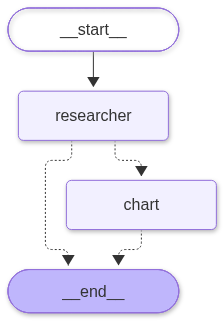

In [23]:
#에이전트끼리 엣지로 연결할 필요가 없어 간단해짐
builder = StateGraph(ChartState)
builder.add_node("researcher", researcher)
builder.add_node("chart",chart)
builder.add_edge(START, "researcher") # 에이전트에서 종료를 end로 처리해 여기에 end 필요없음
network_chart = builder.compile()
network_chart

In [27]:
plt.rcParams['font.family'] = 'Malgun Gothic'

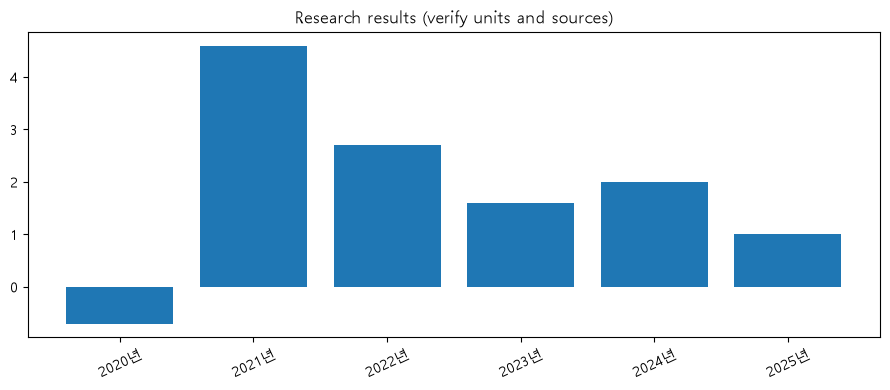

In [28]:
result = network_chart.invoke({"question":"2020년부터 2025년까지 한국의 연도별 실질 GDP 성장률(%)"}, config={"recursion_limit":5})

### 멀티 에이전트 기반(네트워크) AI 맞춤형 학습 진단 및 문제 출제 시스템
학생의 과목별 학습 점수를 분석하여 가장 취약한 학습 영역을 찾아내고, 해당 영역에 대한 맞춤형 문제를 자동으로 출제하는 AI 학습 진단 멀티 에이전트 시스템을 개발

- Diagnosis Agent: 학생의 영역별 점수를 분석하고 가장 취약한 영역을 찾아 학습 진단 결과를 작성
- Quiz Agent: 진단 결과를 전달받아 취약 영역에 대한 객관식 문제를 생성

```
scores = {"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}

1. 학생의 학습 점수를 입력받음
2. 모든 점수가 0~100점 사이인지 검사
3. 가장 점수가 낮은 학습 영역을 찾음
4. LLM을 이용하여 학생의 학습 상태를 3문장으로 진단
5. 진단 결과를 문제 출제 에이전트에게 전달
6. LLM을 이용하여 취약 영역에 대한 객관식 문제 3개를 생성
7. 각 문제에 정답과 해설을 포함
8. 최종 진단 결과와 생성된 문제를 출력
```

In [3]:
class StudyState(TypedDict,total=False):
    scores: dict[str,int]
    weakness: str
    diagnosis: str
    quiz: list[dict]

def diagnosis(state:StudyState)->Command[Literal['quiz']]:
    scores = state['scores']
    if not scores or any (not 0 <= v <= 100 for v in scores.values()):
        raise ValueError('영역별 점수를 0 ~ 100 사이로 입력하세요.')
    weak = min(scores, key=scores.get)
    explanation = ask("당신은 친절한 학습 진단 전문가입니다. 점수의 의미를 과장하지 말고 3문장으로 분석하세요.", f"영역별 점수: {scores}, 최저 영역:{weak}")

    return Command(update={'weakness':weak, 'diagnosis':explanation},goto='quiz')

def quiz(state:StudyState)->Command[Literal['__end__']]:
    content = ask('당신은 학습문제 출제 전문가입니다. 지정된 취약 영역에 대해 객관식 3문제를 만들고 각 문항에 정답과 쉬운 해설을 붙이세요. 애매한 문항은 피하세요.', f"취약 영역:{state['weakness']}\n진단: {state['diagnosis']}")
    return Command(update={'quiz':content},goto=END)

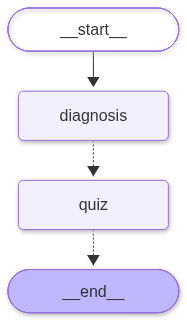

In [4]:
builder = StateGraph(StudyState)
builder.add_node("diagnosis",diagnosis)
builder.add_node("quiz",quiz)
builder.add_edge(START,"diagnosis")
study_network = builder.compile()
study_network

In [9]:
result = study_network.invoke({"scores":{"파이썬 기초문법": 90, "데이터 분석": 75, "딥러닝": 60}}, config={'recursion_limit':5})

In [10]:
print('[진단]',result['diagnosis'],'\n[문제]',result['quiz'])

[진단] 파이썬 기초문법은 90점으로 기본 문법 활용 능력이 비교적 안정적이며, 데이터 분석은 75점으로 핵심 개념을 이해하고 있으나 추가 연습이 필요해 보입니다.  
딥러닝은 60점으로 다른 영역보다 보완이 필요하지만, 점수만으로 학습 능력을 단정하기보다는 기초 수학·모델 구조·실습 경험 중 어느 부분이 어려운지 확인하는 것이 좋습니다.  
우선 신경망의 기본 개념과 간단한 예제 구현을 반복하고, 데이터 분석에서 익힌 전처리·시각화 능력을 딥러닝 실습에 연결해 보세요. 
[문제] ## 딥러닝 객관식 문제 3문항

### 1번. 신경망의 기본 구조
다음 중 인공 신경망에서 **가중치(weight)**의 역할로 가장 알맞은 것은 무엇인가요?

① 입력 데이터의 개수를 자동으로 늘린다.  
② 각 입력값이 결과에 미치는 영향의 크기를 조절한다.  
③ 학습 데이터를 정답 데이터로 변환한다.  
④ 손실 함수의 종류를 결정한다.  

**정답: ②**

**해설:**  
가중치는 각 입력값에 곱해져 결과에 미치는 영향의 크기를 조절합니다. 신경망은 학습 과정에서 가중치를 조금씩 수정하며 예측 성능을 높입니다.

---

### 2번. 활성화 함수 계산
ReLU 함수는 다음과 같이 정의됩니다.

\[
\text{ReLU}(x)=\max(0,x)
\]

입력값이 `-3`, `0`, `5`일 때 각각의 ReLU 출력으로 올바른 것은 무엇인가요?

① `-3, 0, 5`  
② `0, 0, 5`  
③ `0, 5, 5`  
④ `3, 0, -5`  

**정답: ②**

**해설:**  
ReLU는 음수를 모두 `0`으로 바꾸고, 양수는 그대로 출력합니다. 따라서 `-3 → 0`, `0 → 0`, `5 → 5`입니다.

---

### 3번. 신경망 학습 과정
신경망 학습에서 **역전파(backpropagation)**의 주요 역할은 무엇인가요?

① 입력 데이터를 무작위로 섞는 것  
② 예측값과 실제값의 차이를 이용해 가중치의 기울기를 계산하는 것  
③ 이미지의 크기

### 2. Supervisor
- Supervisor가 여러 전문 에이전트에게 작업을 순서대로 맡기고, 모든 작업이 끝나면 결과를 반한하는 구조

In [20]:
class TripState(TypedDict, total=False):
    request: str            # 사용자의 여행 요청
    sources: list[dict]     # 웹 검색 결과
    research: str           # 조사 에이전트가 작성한 요약
    recommendation: str     # 추천 에이전트가 작성한 결과
    saved_path: str         # 저장된 파일 경로
    next_step: str          # LLM이 선택한 다음 작업
    error: str              # 오류 정보를 기록하기 위한 필드

class RouteDecision(BaseModel):
    next_step: Literal["search_agent", "recommend_agent","save_agent","FINISH"]

In [21]:
router_llm = llm.with_structured_output(RouteDecision)

In [22]:
def supervisor(state: TripState) -> Command[Literal['search_agent', 'recommend_agent','save_agent','__end__']]: # 모두 관리해서 어디든 갈 수 있음
    completed = {"search_agent":bool(state.get('research')), "recommend_agent":bool(state.get("recommendation")),"save_agent":bool(state.get("saved_path"))}

    if all(completed.values()): # all : 내부에 있는 모든 값들이 True일 때 True 반환
        return Command(goto=END)

    decision = router_llm.invoke([
        ('system', '당신은 여행 작업 감독자입니다. 반드시 검색>추천>저장 순서로 진행하세요. 이미 완료한 작업은 반복하지 마세요. 다음 작업 이름만 선택하세요.'),
        ('human', json.dumps({'request': state['request'], "completed":completed}, ensure_ascii=False))

    ])

# 이터러블 : 순서,인덱싱을 보장하지 않음. 자료가 모여있는 구조. 
# iter() : 객체가 순서를 가지게 되어 차례대로 나열할 수 있게 됨.
# 이터레이터: iter()로 감싸면 이터러블은 이터레이터가 됨
# next() : iter()가  next()를 통해 하나씩 꺼낼 수 있음

# for문에 리스트를 넣으면 내부적으로 iter로 감싸져 순서가 생김. ex) for i in [1,2,3]:

    expected = next(k for k, v in completed.items() if not v) # next: 
    return Command(update={"next_step":decision.next_step}, goto=expected)

In [23]:
def trip_search(state:TripState) -> Command[Literal['supervisor']]:
    sources = search_web(state['request'] + '여행 추천 관광지 날씨 예보')
    text = ask('여행 조사원입니다. 출처에 근거한 내용만 요약하고 날짜가 확인되지 않은 날씨는 확정하지 마세요.',json.dumps(sources, ensure_ascii=False))
    return Command(update={'sources':sources, 'research':text}, goto='supervisor')

def trip_recommend(state: TripState) -> Command[Literal['supervisor']]:
    text = ask('여행 추천 전문가입니다. 조사 내용을 바탕으로 여행지 3곳과 이유, 날씨 확인 주의사항을 작성하세요. 검증되지 않은 운영시간, 예보는 쓰지 마세요.', state['request']+"\n"+state['research'])
    return Command(update={'recommendation':text}, goto='supervisor')

def trip_save(state:TripState) -> Command[Literal['supervisor']]:
    path = OUTPUT_DIR / 'trip_recommendation.md'
    refs = '\n'.join('- '+s["url"] for s in state.get('sources', []))
    path.write_text('# 여행 추천\n\n'+state['recommendation']+'\n\n### 참고 검색 링크\n'+refs, encoding='utf-8')
    return Command(update={'saved_path':str(path)},goto='supervisor')


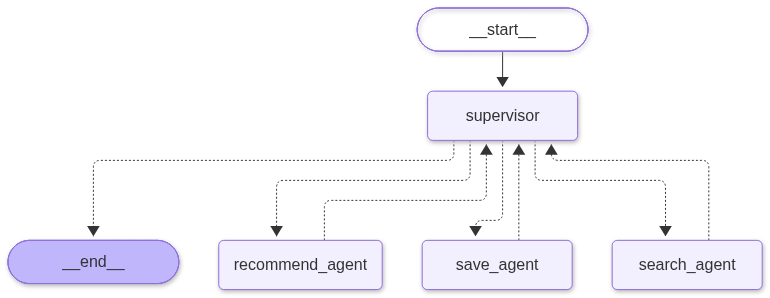

In [24]:
builder = StateGraph(TripState)
for name, fn in [('supervisor',supervisor),('search_agent',trip_search),('recommend_agent',trip_recommend),('save_agent',trip_save)]:
    builder.add_node(name,fn)
builder.add_edge(START, 'supervisor')
trip_graph = builder.compile()
trip_graph

In [25]:
result = trip_graph.invoke({'request':"제주도 2박 3일 자연 경관 중심 여행지를 추천해줘"}, config={"recursion_limit":10})

In [26]:
print(result['recommendation'])
print('저장 파일:',result['saved_path'])

## 제주도 2박 3일 자연경관 중심 추천 3곳

### 1. 성산일출봉–섭지코지 일대
**추천 이유**
- 제주 동부의 대표적인 화산 지형과 해안 풍경을 한 번에 볼 수 있습니다.
- 성산일출봉은 분화구 지형을, 섭지코지는 해안 절벽·초지·등대 풍경을 즐기기 좋습니다.
- 두 장소를 같은 날 묶기 좋아 첫날 일정으로 적합합니다.

**추천 일정**
- 성산일출봉
- 섭지코지 해안 산책
- 시간이 남으면 광치기해변 또는 성산 주변 해안도로

**주의사항**
- 강풍이나 비가 있으면 해안 산책로가 미끄러울 수 있습니다.
- 성산일출봉의 탐방 가능 구간과 입장 관련 사항은 방문 전 공식 안내를 확인하세요.
- 일출을 계획한다면 일출 시각뿐 아니라 당일 구름량과 바람도 함께 확인하는 것이 좋습니다.

---

### 2. 한라산 또는 사려니숲길
**추천 이유**
- 해안 풍경과 다른 제주 내륙의 숲·오름 경관을 경험할 수 있습니다.
- 체력과 일정에 따라 선택할 수 있어 2일 차 자연 체험지로 활용하기 좋습니다.

**선택 기준**
- **등산을 원할 때:** 한라산 탐방로  
- **비교적 완만한 숲길을 원할 때:** 사려니숲길
- **짧은 조망 산책을 원할 때:** 금오름 등 서부 오름

**주의사항**
- 한라산은 코스별 탐방 예약, 통제, 입산 기준이 달라질 수 있으므로 반드시 한라산국립공원 공식 공지를 확인해야 합니다.
- 산 정상과 해안의 기온·바람 차이가 크므로 방풍 재킷과 미끄럼 방지 신발을 준비하세요.
- 비·안개·강풍이 예상되면 등산보다 숲길이나 해안 산책으로 일정을 조정하는 편이 안전합니다.

---

### 3. 중문 주상절리–서귀포 해안
**추천 이유**
- 육각형 기둥 모양의 주상절리와 서귀포 해안의 절벽 풍경을 볼 수 있습니다.
- 중문권 숙소와 연결하기 편하고, 날씨가 좋지 않을 때도 비교적 짧은 산책 중심으로 일정을 조정하기 좋습니다.

**추천 일정**
- 주상절리대
- 중문 해안 산책
- 날씨와 체력에 따라 천제연폭포 또는 서귀포 

### 3. Hierarchical
- 팀 내부에 여러 작업 노드를 두고, 각 팀을 독립적인 Subgraph(하위 그래프)로 구성하는 방식
- 계층형 멀티 에이전트

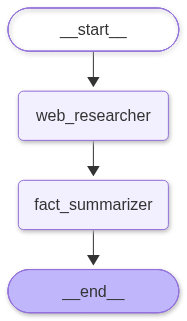

In [ ]:
class ResearchTeamState(TypedDict, total=False):
    topic: str              # 조사할 주제
    sources: list[dict]     # 웹 검색 결과
    notes: str              # 검색 결과를 요약한 조사 노트

def find_sources(s:ResearchTeamState):
    return {'sources':search_web(s['topic'])}

def summarize_sources(s: ResearchTeamState):
    return {'notes': ask('당신은 조사 전문가입니다. 제공된 검색 결과만 바탕으로 핵심 사실을 요약하고 불확실한 부분은 표시하세요.',json.dumps(s['sources'],ensure_ascii=False))}

research_builder = StateGraph(ResearchTeamState)
research_builder.add_node('web_researcher', find_sources)
research_builder.add_node('fact_summarizer',summarize_sources)
research_builder.add_edge(START, 'web_researcher')
research_builder.add_edge('web_researcher','fact_summarizer')
research_builder.add_edge('fact_summarizer',END)
research_team = research_builder.compile()
research_team

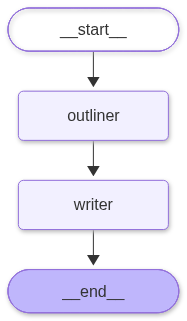

In [ ]:
class WritingTeamState(TypedDict, total=False):
    topic: str          # 보고서 주제
    notes: str          # 조사팀에서 작성한 조사 노트
    outline : str       # 보고서 목차 및 개요
    report: str         # 최종 보고서

def outline_writer(s: WritingTeamState):
    return {'outline':ask('당신은 문서 기획자입니다. 조사 노트만을 활용하여 제목과 3~4개 소제목으로 개요를 만드세요.', s['topic']+"\n"+s['notes'])}

def report_writer(s:WritingTeamState):
    return {"report":ask('당신은 보고서 작성 전문가입니다. 개요와 조사 노트만을 사용하여 한국어 마크다운 보고서를 작성하세요. 불확실한 정보는 불확실하닥 표시하세요.',json.dumps(s, ensure_ascii=False))}

writing_builder = StateGraph(WritingTeamState)
writing_builder.add_node('outliner', outline_writer)
writing_builder.add_node('writer',report_writer)
writing_builder.add_edge(START, 'outliner')
writing_builder.add_edge('outliner', 'writer')
writing_builder.add_edge('writer', END)
writing_team = writing_builder.compile()
writing_team

In [31]:
class TopState(TypedDict, total=False):
    topic: str
    notes: str
    sources : list[dict]
    outline: str
    report: str
    saved_path: str

class TeamChoice(BaseModel):
    team: Literal["research_team", "writing_team", "FINISH"]

top_router = llm.with_structured_output(TeamChoice)

def top_supervisor(s:TopState) -> Command[Literal["research_team","writing_team","__end__"]]:
    if s.get('report'):
        return Command(goto=END)
    choice = top_router.invoke([
        ('system','상위 감독자입니다. 조사 노트가 없으면 research_team, 조사 노트가 있고 보고서가 없으면 writing_team을 선택하세요.'),
        ('human', json.dumps({'topic':s['topic'], 'has_notes':bool(s.get('notes')),'has_report':bool(s.get('report'))}, ensure_ascii=False))
    ])
    expected = 'writing_team' if s.get('notes') else 'research_team'
    return Command(goto=expected)

def run_research(s:TopState) -> Command[Literal['top_supervisor']]:
    out = research_team.invoke({'topic':s['topic']}, config={'recursion_limit':10})
    return Command(update={'notes':out['notes'], 'sources':out['sources']}, goto='top_supervisor')

def run_writing(s:TopState) -> Command[Literal['top_supervisor']]:
    out = writing_team.invoke({'topic':s['topic'], 'notes':s['notes']}, config={'recursion_limit':10})
    path = OUTPUT_DIR / 'agent_report.md'
    refs = "\n".join("- " + x['url'] for x in s['sources'])
    path.write_text(out['report']+"\n\n### 검색 출처\n"+refs, encoding="utf-8")
    return Command(update={'outline':out['outline'], 'report':out['report'], 'saved_path':str(path)}, goto='top_supervisor')

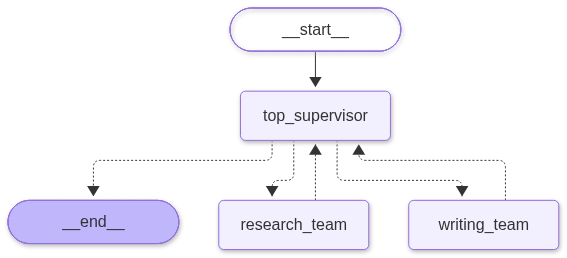

In [33]:
top_builder = StateGraph(TopState)
top_builder.add_node('top_supervisor',top_supervisor)
top_builder.add_node('research_team',run_research)
top_builder.add_node('writing_team',run_writing)
top_builder.add_edge(START, 'top_supervisor')
hierarchical_graph = top_builder.compile()
hierarchical_graph


In [34]:
result = hierarchical_graph.invoke({'topic':'멀티 에이전트 시스템의 개념과 실제 활용 사례'}, config={'recursion_limit':10})
print(result['report'])
print('보고서 저장: ',result['saved_path'])

# 멀티 에이전트 시스템의 개념과 실제 활용 사례

## 1. 멀티 에이전트 시스템의 개념과 핵심 구조

### 1.1 멀티 에이전트 시스템이란

멀티 에이전트 시스템(Multi-Agent System, MAS)은 여러 AI 에이전트가 각자의 전문 역할을 수행하면서 정보를 교환하고 협력해 공동 목표를 달성하는 분산형 AI 아키텍처이다.

여기서 에이전트는 특정 업무를 수행하도록 설계된 AI 구성 요소를 의미한다. 예를 들어 한 에이전트는 고객 문의를 분류하고, 다른 에이전트는 관련 문서를 검색하며, 또 다른 에이전트는 최종 답변을 작성할 수 있다.

MAS는 단순히 AI 모델이나 프로그램을 여러 개 배치하는 것과 구별된다. 여러 에이전트가 하나의 시스템으로 기능하려면 다음 요소가 함께 설계되어야 한다.

- 에이전트별 역할과 전문성
- 에이전트 간 통신 방식
- 업무 분담과 핸드오프
- 의사결정 및 상태 관리
- 충돌과 의견 불일치 조정
- 공동 목표에 대한 정렬
- 기존 데이터베이스 및 업무 시스템과의 연계

따라서 MAS의 핵심은 에이전트의 개수 자체가 아니라 **에이전트 간 관계와 조정 구조**에 있다.

### 1.2 핵심 구성 요소

#### 역할과 전문성

각 에이전트는 특정 업무나 도메인에 집중한다. 업무를 전문 영역별로 나누면 하나의 에이전트가 모든 작업을 처리하는 방식보다 복잡한 업무를 체계적으로 구성할 수 있다.

#### 통신과 정보 교환

에이전트는 요청, 알림, 작업 결과 등의 정보를 주고받으며 협력한다. 통신은 구조화된 메시지 교환 방식으로 구현될 수 있으며, 자료에서는 FIPA ACL이 에이전트 통신 언어의 한 사례로 소개된다. 다만 제공된 자료만으로 이 표준이 실제 MAS에서 얼마나 널리 사용되는지는 확인되지 않는다.

#### 핸드오프와 업무 흐름

한 에이전트가 처리한 작업을 다음 에이전트에게 넘기는 과정을 에이전트 핸드오프라고 한다. 예를 들어 고객 문의 접수 후 문서 검색, 답변 작성, 환불 처리 순으로 업무를 연결할 수 있

# 2. 종합 문제

### AI 소프트웨어 개발팀 구축
- Hierarchical 멀티 에이전트 구조로 직접 설계하고 구현
- AI 기반 소프트웨어 개발 자동화 서비스를 만드는 개발자
```
    학생 성적 관리 프로그램을 만들어줘. 학생 이름과 점수를 등록할 수 있고, 전체 학생 목록 조회, 평균 점수 계산, 최고 점수 학생 조회 기능이 필요해
```
- 기존의 단일 LLM 시스템은 이 요청을 받아 한 번에 코드를 생성(x)
    - 기획팀: 사용자 요구사항을 분석하고 프로그램의 구조를 설계
    - 개발팀: 설계서를 바탕으로 Python 코드를 작성하고 품질을 검토
    - 상위 감독자: 기획팀과 개발팀의 작업 순서를 관리하고 최종 결과물을 완성

### 요구사항
1. Top Supervisor
- 전체적인 프로젝트 진행을 관리하는 상위 감독자를 구현
- 현재 State를 확인하고 아래 규칙에 따라 작업을 배배정
    - 설계서가 없다면 planning_team 실행
    - 설계서가 있고, 코드가 없다면 development_team 실행
    - 코드가 있고, 검토를 통과했다면 END
    - 코드 검토에 실패했다면 개발팀에 수정 요청

2. planing Team
- 기획팀 작업 순서 결정 노드
- 사용자 요구사항 분석 노드
- 함수, 자료구조, 프로그램 구조 설계 노드
- 기획팀의 최종 출력에는 아래 내용이 포함되어야 햠
    - 프로젝트 목적
    - 필수 기능 목록
    - 사용할 자료구조
    - 함수 목록 및 함수별 역할
    - 예외 처리 요구사항

3. Development Team
- 개발 작업 순서 및 재작업 관리 노드
- 설계서 기반 Python 코드 작성
- 코드 품질 및 요구사항 충족 여부 검토
    - 필수 기능이 모두 구현되었는지
    - 문법적으로 올바른 Python 코드인지
    - 함수가 적절하게 분리되었는지
    - 예외 상황이 처리되었는지
    - 코드의 가독성이 적절한지